(sec-8-1)=
# 8.1 Filter Types and Specifications

Before choosing an ECG filter, I ask what I want to keep and what I want to reduce. Slow baseline drift, a narrow power-line component, and rapid muscle activity call for different choices. A filter can help when the signal and disturbance differ in useful ways, but it can also change the waves we want to measure.

We will connect the common filter names to their frequency responses, then translate a practical goal into a specification. Cutoff frequency is only part of that specification: attenuation, transition width, and timing changes matter as well.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-8-1-1)=
## 8.1.1 What Filters Do

I find it useful to sort the uses of filters into three broad jobs.

A filter can **modify** a signal, reshaping its spectrum without trying to throw anything away. A differentiator that emphasizes the steep slopes of the QRS complex is an example; so is the de-emphasis network in a hearing aid. A filter can **extract** a feature that is mixed with other activity, such as the 8–13 Hz alpha rhythm from a broadband EEG, or the slow respiratory modulation riding on a PPG. And a filter can **remove** something we never wanted: power-line hum, baseline wander, electrode noise, muscle artifact. The mathematics is identical in all three cases; what differs is which part of the output we care about.

Filters also come in two physical forms. The first is an **analog circuit**: resistors, capacitors and operational amplifiers that act on a voltage before it is ever digitized. Every biopotential amplifier contains such circuits, and one of them, the anti-aliasing low-pass filter in front of the analog-to-digital converter, cannot be replaced by anything digital, because aliasing happens at the moment of sampling ([Section 6.2](../ch09_sampling/index.md)). The second form is a **mathematical algorithm** applied to the sampled sequence $x[n]$, running on a microcontroller, a phone or a laptop. Digital filters are exactly reproducible, they do not drift with temperature, they can be changed with a line of code, and, when the whole recording is available, they can even use "future" samples. Most of this part of the book is about the digital form.

A digital filter can be applied in either of two domains. In the **time domain** we compute each output sample from input samples, either by the convolution sum

(eq-8-1)=
\begin{equation*}
y[n] = \sum_{k} h[k]\, x[n-k] \tag{8.1}
\end{equation*}

At a fixed output index $n$, each coefficient $h[k]$ weights an input sample $x[n-k]$. We multiply those pairs and add them to obtain $y[n]$. For example, $h[0]=h[1]=1/2$, with all other coefficients zero, gives $y[n]=(x[n]+x[n-1])/2$. This makes the idea of filtering concrete before we describe it in terms of frequencies.

or by a recursive difference equation (Section 5.5). In the **frequency domain** we transform the signal, multiply by the desired response and transform back,

(eq-8-2)=
\begin{equation*}
Y(e^{j\Omega}) = H(e^{j\Omega})\, X(e^{j\Omega}). \tag{8.2}
\end{equation*}

With the FFT this second route becomes: compute $X[k]$, multiply by $H[k]$, compute the inverse FFT. The convolution theorem says the two routes agree, with one practical caveat. The DFT product corresponds to *circular* convolution, so to reproduce the linear convolution [(8.1)](#eq-8-1) of an $L$-sample signal with an $M$-tap filter, both sequences must first be zero-padded to at least $L + M - 1$ samples. The next cell checks this on two seconds of ECG and a 31-tap low-pass filter (designed with `signal.firwin`, a routine we build ourselves in [Chapter 9](../ch14_fir/index.md)).

In [2]:
fs = 360
rec = wfdb.rdrecord("../data/mitdb/105", channels=[0], sampfrom=0, sampto=2 * fs)
x = rec.p_signal[:, 0]
h = signal.firwin(31, 40, fs=fs)

y_time = np.convolve(x, h)                                  # equation (13.1)
n_lin = x.size + h.size - 1
y_freq = np.fft.irfft(np.fft.rfft(x, n_lin) * np.fft.rfft(h, n_lin), n_lin)   # equation (13.2)
y_circ = np.fft.irfft(np.fft.rfft(x) * np.fft.rfft(h, x.size), x.size)        # no zero-padding

print(f"Signal length L = {x.size}, filter length M = {h.size}, L + M - 1 = {n_lin}")
print(f"max |time - FFT (padded)|   = {np.max(np.abs(y_time - y_freq)):.2e} mV")
print(f"max |time - FFT (unpadded)| = {np.max(np.abs(y_time[:x.size] - y_circ)):.2e} mV")

Signal length L = 720, filter length M = 31, L + M - 1 = 750
max |time - FFT (padded)|   = 4.44e-16 mV
max |time - FFT (unpadded)| = 1.13e+00 mV


With proper padding the two outputs agree to rounding error. Without it, the tail of the convolution wraps around and corrupts the first $M-1$ output samples, here by more than 1 mV, as much as the height of a QRS complex. Which route is faster depends on the filter length: direct convolution costs about $M$ multiplications per output sample, the FFT route about $\log_2$ of the transform length, so the frequency domain wins for long filters. Library routines such as `scipy.signal.oaconvolve` and `fftconvolve` make that choice for us.

(sec-8-1-2)=
## 8.1.2 The Four Ideal Frequency-Selective Filters

A **frequency-selective** filter divides the frequency axis into bands that are passed unchanged (**passbands**) and bands that are blocked (**stopbands**). The ideal versions have a gain of exactly one in the passband, exactly zero in the stopband, an instantaneous jump between them and zero phase everywhere. With cutoff frequencies $0 < \Omega_c, \Omega_1, \Omega_2 < \pi$ (in radians per sample; recall $\Omega = 2\pi f / f_s$), and for $|\Omega| \le \pi$:

- **Low-pass** (LP): $H_{\text{LP}}(e^{j\Omega}) = 1$ for $|\Omega| \le \Omega_c$ and $0$ otherwise.
- **High-pass** (HP): $H_{\text{HP}}(e^{j\Omega}) = 0$ for $|\Omega| < \Omega_c$ and $1$ otherwise.
- **Band-pass** (BP): $H_{\text{BP}}(e^{j\Omega}) = 1$ for $\Omega_1 \le |\Omega| \le \Omega_2$ and $0$ otherwise.
- **Band-stop** (BS): $H_{\text{BS}}(e^{j\Omega}) = 0$ for $\Omega_1 < |\Omega| < \Omega_2$ and $1$ otherwise. A band-stop filter with a very narrow stopband is called a **notch** filter.

Like every DTFT, these responses repeat with period $2\pi$, and because we want real-valued impulse responses they are even functions of $\Omega$, so it is enough to draw them on $0 \le \Omega \le \pi$. The four types are not independent. Directly from the definitions,

(eq-8-3)=
\begin{equation*}
H_{\text{HP}} = 1 - H_{\text{LP}}, \qquad
H_{\text{BP}} = H_{\text{LP}}^{(\Omega_2)} - H_{\text{LP}}^{(\Omega_1)}, \qquad
H_{\text{BS}} = 1 - H_{\text{BP}}, \tag{8.3}
\end{equation*}

where the superscript gives the cutoff of the low-pass filter. Once we know how to build a low-pass filter we can, in principle, build the other three. [Section 14.2](../ch14_fir/index.md) uses exactly this trick, called spectral inversion, to design FIR high-pass and band-stop filters.

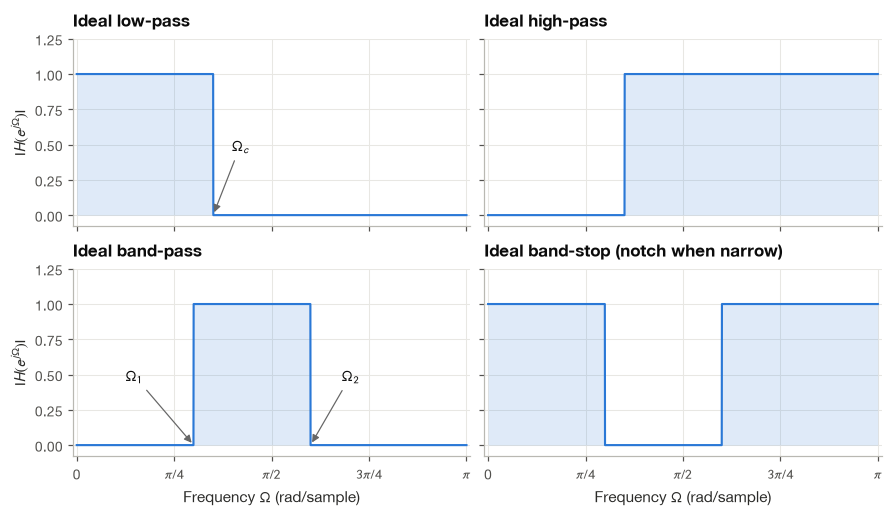

In [3]:
Om = np.linspace(0, np.pi, 2001)
Oc, O1, O2 = 0.35 * np.pi, 0.3 * np.pi, 0.6 * np.pi
lp = (Om <= Oc).astype(float)
ideal = {"Ideal low-pass": lp,
         "Ideal high-pass": 1 - lp,
         "Ideal band-pass": ((Om >= O1) & (Om <= O2)).astype(float),
         "Ideal band-stop (notch when narrow)": 1 - ((Om > O1) & (Om < O2)).astype(float)}

fig, axes = plt.subplots(2, 2, figsize=(8, 4.6), sharex=True, sharey=True)
for ax, (title, H) in zip(axes.ravel(), ideal.items()):
    ax.fill_between(Om, H, color=C[0], alpha=0.15, lw=0)
    ax.plot(Om, H, color=C[0])
    ax.set(title=title, ylim=(-0.08, 1.25))
for ax in axes[1]:
    ax.set_xticks([0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi],
                  ["0", r"$\pi/4$", r"$\pi/2$", r"$3\pi/4$", r"$\pi$"])
    ax.set_xlabel(r"Frequency $\Omega$ (rad/sample)")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$|H(e^{j\Omega})|$")
axes[0, 0].annotate(r"$\Omega_c$", (Oc, 0), xytext=(Oc + 0.15, 0.45),
                    arrowprops=dict(arrowstyle="-|>", color="0.4", lw=0.8))
axes[1, 0].annotate(r"$\Omega_1$", (O1, 0), xytext=(O1 - 0.55, 0.45),
                    arrowprops=dict(arrowstyle="-|>", color="0.4", lw=0.8))
axes[1, 0].annotate(r"$\Omega_2$", (O2, 0), xytext=(O2 + 0.25, 0.45),
                    arrowprops=dict(arrowstyle="-|>", color="0.4", lw=0.8))
plt.show()

(sec-8-1-3)=
## 8.1.3 Why Ideal Filters Cannot Be Built

To see what an ideal low-pass filter would require, we compute its impulse response with the inverse DTFT (Section 10.1). The continuous-time version of this calculation, which gives the familiar sinc pulse, appears in Section 8.2; the discrete-time version runs as follows.

**Step 1: write the inverse DTFT.** Because $H_{\text{LP}}$ equals one on $[-\Omega_c, \Omega_c]$ and zero elsewhere in $[-\pi, \pi]$, the integral shrinks to the passband:

$$
h_{\text{LP}}[n] = \frac{1}{2\pi}\int_{-\pi}^{\pi} H_{\text{LP}}(e^{j\Omega})\, e^{j\Omega n}\, d\Omega
= \frac{1}{2\pi}\int_{-\Omega_c}^{\Omega_c} e^{j\Omega n}\, d\Omega .
$$

**Step 2: integrate for $n \neq 0$.** The antiderivative of $e^{j\Omega n}$ with respect to $\Omega$ is $e^{j\Omega n}/(jn)$, so

$$
h_{\text{LP}}[n] = \frac{1}{2\pi}\cdot\frac{e^{j\Omega_c n} - e^{-j\Omega_c n}}{jn}
= \frac{1}{\pi n}\cdot\frac{e^{j\Omega_c n} - e^{-j\Omega_c n}}{2j}
= \frac{\sin(\Omega_c n)}{\pi n},
$$

where the last step is Euler's formula for the sine.

**Step 3: treat $n = 0$ separately.** There the integrand is one, and the integral is the length of the interval divided by $2\pi$, that is, $h_{\text{LP}}[0] = 2\Omega_c / (2\pi) = \Omega_c/\pi$. This is also the limit of $\sin(\Omega_c n)/(\pi n)$ as $n \to 0$, so a single formula covers every $n$:

(eq-8-4)=
\begin{equation*}
h_{\text{LP}}[n] = \frac{\sin(\Omega_c n)}{\pi n} = \frac{\Omega_c}{\pi}\,\operatorname{sinc}\!\left(\frac{\Omega_c n}{\pi}\right), \qquad -\infty < n < \infty, \tag{8.4}
\end{equation*}

with the normalized $\operatorname{sinc}(u) = \sin(\pi u)/(\pi u)$ used by NumPy. Three properties of [(8.4)](#eq-8-4) rule out a practical implementation.

1. **It never ends.** $h_{\text{LP}}[n]$ is nonzero for infinitely many $n$, so no finite convolution can compute it exactly.
2. **It is noncausal.** It is nonzero for negative $n$ as well. A system with $h[n] \neq 0$ for $n < 0$ needs future input samples to produce the present output (Section 4.3). Worse, it needs *all* of them, infinitely far into the future.
3. **It is not even BIBO stable.** The envelope of $|h_{\text{LP}}[n]|$ decays only like $1/(\pi|n|)$. Since the average of $|\sin(\Omega_c n)|$ over many samples is $2/\pi$, the partial sums behave like $\sum_{n=1}^{N} \frac{2}{\pi^2 n} \approx \frac{2}{\pi^2}\ln N$ on each side. This grows without bound, so $\sum_n |h[n]| = \infty$, and a bounded input can be found that drives the output to infinity.

The same argument applies to the other three types through [(8.3)](#eq-8-3), because each is a combination of low-pass responses and impulses. There is also a deeper reason, known as the Paley–Wiener theorem: the magnitude response of a causal, stable filter can vanish only at isolated frequencies, never over a whole band {cite:p}`oppenheim2010`. A real filter can make the stopband very small, but never exactly zero.

The next cell checks [(8.4)](#eq-8-4) against a direct numerical evaluation of the inverse DTFT integral and watches the absolute sum grow logarithmically. We use the cutoff $f_c = 40$ Hz at $f_s = 360$ Hz, a common low-pass setting for ECG monitoring.

In [4]:
fs = 360
Oc = 2 * np.pi * 40 / fs                       # 40 Hz cutoff in rad/sample


def ideal_lowpass(n, Oc):
    """Impulse response of the ideal low-pass filter, equation (13.4)."""
    return Oc / np.pi * np.sinc(Oc * n / np.pi)


n = np.arange(-8, 9)
Om_grid = np.linspace(-Oc, Oc, 200001)
h_numeric = np.array([np.trapezoid(np.exp(1j * Om_grid * k), Om_grid).real / (2 * np.pi) for k in n])
print(f"max |closed form - numerical integral| = {np.max(np.abs(ideal_lowpass(n, Oc) - h_numeric)):.1e}")

print(f"predicted growth per tenfold N: (4/pi^2) ln 10 = {4 / np.pi**2 * np.log(10):.3f}")
previous = None
for N in [10, 100, 1000, 10_000, 100_000]:
    k = np.arange(1, N + 1)
    total = Oc / np.pi + 2 * np.sum(np.abs(ideal_lowpass(k, Oc)))
    growth = "" if previous is None else f"   (growth {total - previous:.3f})"
    print(f"sum of |h[n]| for |n| <= {N:>6}: {total:6.3f}{growth}")
    previous = total

max |closed form - numerical integral| = 8.9e-12
predicted growth per tenfold N: (4/pi^2) ln 10 = 0.933
sum of |h[n]| for |n| <=     10:  1.500
sum of |h[n]| for |n| <=    100:  2.423   (growth 0.923)
sum of |h[n]| for |n| <=   1000:  3.346   (growth 0.924)
sum of |h[n]| for |n| <=  10000:  4.270   (growth 0.924)
sum of |h[n]| for |n| <= 100000:  5.194   (growth 0.924)


Each tenfold increase in $N$ adds about 0.92 to the sum, close to the predicted $(4/\pi^2)\ln 10 \approx 0.93$: the sum grows logarithmically and never settles. The impulse response has finite *energy* (its squared values sum to $\Omega_c/\pi$, by Parseval's relation), but it is not absolutely summable.

What happens if we do the obvious thing, keep only $2K+1$ samples around $n = 0$ and delay them by $K$ samples so the filter becomes causal? The left panel below shows the ideal impulse response; the right panel shows the magnitude responses of truncated versions of increasing length. The transition from passband to stopband becomes steeper as $K$ grows, but the ripple next to the edge does not shrink: its peak stays near 9% of the jump. This is the **Gibbs phenomenon** of [Section 5.3](../ch07_fourier_series/index.md), now appearing in the frequency domain because truncation in time is multiplication by a rectangular window. How to tame it with smoother windows is the subject of [Section 14.2](../ch14_fir/index.md).

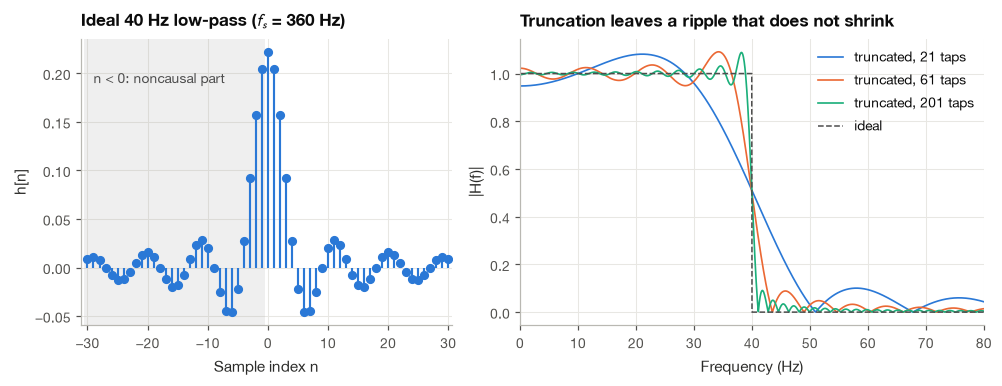

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [1, 1.25]})
n = np.arange(-30, 31)
axes[0].stem(n, ideal_lowpass(n, Oc), linefmt=C[0], markerfmt="o", basefmt=" ")
axes[0].axvspan(-30.5, -0.5, color="0.6", alpha=0.15, lw=0)
axes[0].text(-29, 0.19, "n < 0: noncausal part", fontsize=9, color="0.3")
axes[0].set(xlabel="Sample index n", ylabel="h[n]", title="Ideal 40 Hz low-pass ($f_s$ = 360 Hz)")

f_axis = np.linspace(0, fs / 2, 4000)
for K, color in zip([10, 30, 100], [C[0], C[1], C[2]]):
    hk = ideal_lowpass(np.arange(-K, K + 1), Oc)
    _, Hk = signal.freqz(hk, worN=f_axis, fs=fs)
    axes[1].plot(f_axis, np.abs(Hk), color=color, lw=1.1, label=f"truncated, {2 * K + 1} taps")
axes[1].plot(f_axis, (f_axis <= 40).astype(float), color="0.3", lw=1, ls="--", label="ideal")
axes[1].set(xlim=(0, 80), xlabel="Frequency (Hz)", ylabel="|H(f)|",
            title="Truncation leaves a ripple that does not shrink")
axes[1].legend(loc="upper right")
plt.show()

(sec-8-1-4)=
## 8.1.4 Specifying a Practical Filter

Since perfection is impossible, we describe what is *good enough*. The standard description is a **tolerance scheme**, sketched for a low-pass filter in the figure later in this subsection. It consists of three regions.

- **Passband**, $0 \le \Omega \le \Omega_p$: the gain must stay within $1 \pm \delta_p$, where $\delta_p$ is the **passband ripple** (deviation).
- **Stopband**, $\Omega_s \le \Omega \le \pi$: the gain must stay below $\delta_s$, the **stopband ripple** or stopband deviation.
- **Transition band**, $\Omega_p < \Omega < \Omega_s$: no constraint, except the tacit expectation that the gain falls smoothly. Its width $\Delta\Omega = \Omega_s - \Omega_p$, or $\Delta f = f_s\,\Delta\Omega / (2\pi)$ in hertz, is the **transition width**.

The edges $\Omega_p$ and $\Omega_s$ are the **passband edge** and **stopband edge** frequencies. Four numbers ($\Omega_p$, $\Omega_s$, $\delta_p$, $\delta_s$) therefore define a low-pass specification, and every design method trades them against the filter's complexity: narrower transitions and smaller ripples always cost a longer FIR filter or a higher-order IIR filter.

Data sheets and design programs usually quote ripples in decibels, so we need the conversions.

**Passband ripple in dB.** Inside the passband the gain swings between a maximum of $1 + \delta_p$ and a minimum of $1 - \delta_p$. The peak-to-peak ripple $A_p$ is the ratio of these two gains expressed in dB. Since these are amplitude ratios we use $20\log_{10}$:

(eq-8-5)=
\begin{equation*}
\begin{aligned}
A_p &= 20\log_{10}(1+\delta_p) - 20\log_{10}(1-\delta_p) \\
    &= 20\log_{10}\frac{1+\delta_p}{1-\delta_p} \quad \text{dB}.
\end{aligned} \tag{8.5}
\end{equation*}

For small $\delta_p$ it is useful to linearize. Using $\ln(1 \pm \delta) \approx \pm\delta$ and $\log_{10} u = \ln u / \ln 10$,

$$
A_p \approx \frac{20}{\ln 10}\,\big(\delta_p - (-\delta_p)\big) = \frac{40}{\ln 10}\,\delta_p \approx 17.37\,\delta_p \quad \text{dB}.
$$

A 1% ripple is therefore about 0.17 dB, and a 0.1 dB specification corresponds to $\delta_p \approx 0.0058$.

**Stopband attenuation in dB.** In the stopband the gain is at most $\delta_s$, relative to a nominal passband gain of one. The **minimum stopband attenuation** is

(eq-8-6)=
\begin{equation*}
A_s = -20\log_{10}\delta_s \quad \text{dB}. \tag{8.6}
\end{equation*}

A stopband ripple of $\delta_s = 0.01$ is 40 dB of attenuation, $\delta_s = 0.001$ is 60 dB. (Some texts measure $A_s$ relative to the peak passband gain $1 + \delta_p$; the difference is a fraction of a decibel for any sensible $\delta_p$.)

**Going back from dB.** Solving [(8.5)](#eq-8-5) for $\delta_p$: let $r = 10^{A_p/20}$, then $(1+\delta_p) = r(1-\delta_p)$, which rearranges to

(eq-8-7)=
\begin{equation*}
\delta_p = \frac{10^{A_p/20} - 1}{10^{A_p/20} + 1}, \qquad \delta_s = 10^{-A_s/20}. \tag{8.7}
\end{equation*}

**Example 8.1.1.** A design asks for $\delta_p = 0.01$ and $\delta_s = 0.001$. Then $A_p = 20\log_{10}(1.01/0.99) = 20\log_{10}(1.0202) = 0.1737$ dB, close to the linear estimate $17.37 \times 0.01 = 0.1737$ dB, and $A_s = -20\log_{10}(10^{-3}) = 60$ dB.

**Example 8.1.2.** A data sheet specifies $A_p = 0.5$ dB and $A_s = 40$ dB. From [(8.7)](#eq-8-7), $10^{0.5/20} = 10^{0.025} = 1.0593$, so $\delta_p = 0.0593/2.0593 = 0.0288$, and $\delta_s = 10^{-2} = 0.01$.

In [6]:
def ripple_to_db(dp, ds):
    """Passband ripple and stopband attenuation in dB, equations (13.5) and (13.6)."""
    return 20 * np.log10((1 + dp) / (1 - dp)), -20 * np.log10(ds)


def db_to_ripple(Ap, As):
    """Passband and stopband deviations from dB values, equation (13.7)."""
    r = 10 ** (Ap / 20)
    return (r - 1) / (r + 1), 10 ** (-As / 20)


Ap, As = ripple_to_db(0.01, 0.001)
print(f"Example 13.1.1: Ap = {Ap:.4f} dB (linear approx {17.37 * 0.01:.4f} dB), As = {As:.1f} dB")
dp, ds = db_to_ripple(0.5, 40)
print(f"Example 13.1.2: delta_p = {dp:.4f}, delta_s = {ds:.4f}")
print(f"Round trip: {ripple_to_db(dp, ds)[0]:.4f} dB, {ripple_to_db(dp, ds)[1]:.1f} dB")

Example 13.1.1: Ap = 0.1737 dB (linear approx 0.1737 dB), As = 60.0 dB
Example 13.1.2: delta_p = 0.0288, delta_s = 0.0100
Round trip: 0.5000 dB, 40.0 dB


### Where exactly is "the cutoff"?

The tolerance scheme has two edge frequencies, but people often speak of a single **cutoff frequency**. For most IIR filters, and in most physiology papers, the cutoff means the **−3 dB frequency**, where the gain has fallen to $1/\sqrt{2} \approx 0.707$ and the output power to one half. For windowed FIR filters it usually means the **−6 dB frequency** (gain 0.5), which lies in the middle of the transition band. When a paper reports "a 40 Hz low-pass filter" without saying which definition, the actual passband edge may be several hertz lower. SciPy follows the same split: `signal.butter(N, fc)` places $f_c$ at −3 dB, while `signal.firwin(numtaps, fc)` places it at −6 dB. Both accept frequencies in hertz if we pass `fs=...`; without `fs` they expect frequencies normalized so that 1 is the Nyquist frequency $f_s/2$.

Below, a concrete specification for an ECG low-pass filter at $f_s = 360$ Hz is drawn as a tolerance scheme: passband up to 40 Hz with $\delta_p = 0.05$, stopband from 50 Hz with $\delta_s = 0.01$ (40 dB). I chose an unusually large passband ripple so that it is visible on a linear axis. We meet it with an equiripple FIR filter from `signal.remez`, a method explained in [Section 14.3](../ch14_fir/index.md). With 57 taps, the shortest odd length that meets the specification, the ripples come close to the edges of the boxes and all have the same height, the signature of an optimal design.

In [7]:
fs, fp, fstop = 360, 40, 50
dp, ds = 0.05, 0.01
h_eq = signal.remez(57, [0, fp, fstop, fs / 2], [1, 0], weight=[1, dp / ds], fs=fs)
f_axis, H_eq = signal.freqz(h_eq, worN=4096, fs=fs)
mag = np.abs(H_eq)

pb, sb = f_axis <= fp, f_axis >= fstop
print(f"Filter length: {h_eq.size} taps")
print(f"Passband gain range: {mag[pb].min():.4f} to {mag[pb].max():.4f}  (allowed {1 - dp:.2f} to {1 + dp:.2f})")
print(f"Largest stopband gain: {mag[sb].max():.4f}  ({-20 * np.log10(mag[sb].max()):.1f} dB attenuation)")

Filter length: 57 taps
Passband gain range: 0.9560 to 1.0441  (allowed 0.95 to 1.05)
Largest stopband gain: 0.0089  (41.0 dB attenuation)


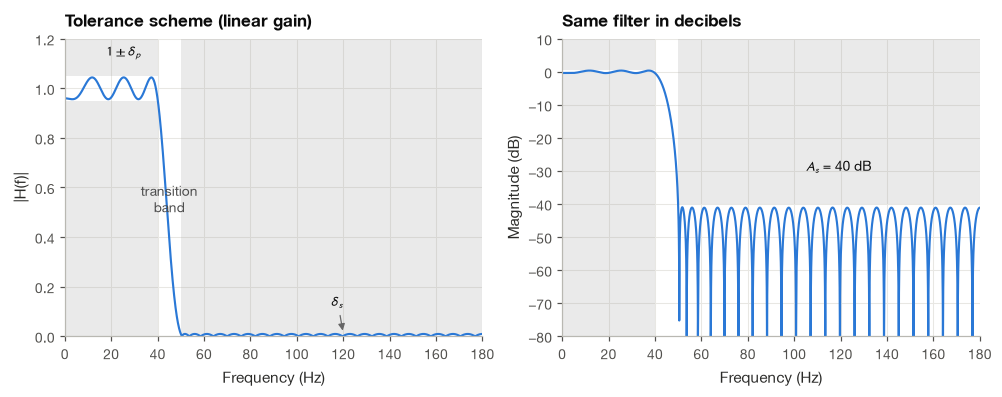

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, db in zip(axes, [False, True]):
    yv = 20 * np.log10(mag) if db else mag
    up, lo = (20 * np.log10(1 + dp), 20 * np.log10(1 - dp)) if db else (1 + dp, 1 - dp)
    stop = 20 * np.log10(ds) if db else ds
    top = 10 if db else 1.2
    bottom = -80 if db else 0
    ax.fill_between([0, fp], up, top, color="0.6", alpha=0.2, lw=0)
    ax.fill_between([0, fp], bottom, lo, color="0.6", alpha=0.2, lw=0)
    ax.fill_between([fstop, fs / 2], stop, top, color="0.6", alpha=0.2, lw=0)
    ax.plot(f_axis, yv, color=C[0])
    ax.set(xlim=(0, fs / 2), ylim=(bottom, top), xlabel="Frequency (Hz)")
axes[0].set(ylabel="|H(f)|", title="Tolerance scheme (linear gain)")
axes[0].annotate(r"$1 \pm \delta_p$", (20, 1.05), xytext=(18, 1.13), fontsize=9)
axes[0].annotate(r"$\delta_s$", (120, ds), xytext=(115, 0.12), fontsize=9,
                 arrowprops=dict(arrowstyle="-|>", color="0.4", lw=0.8))
axes[0].annotate("transition\nband", (45, 0.5), ha="center", fontsize=9, color="0.3")
axes[1].set(ylabel="Magnitude (dB)", title="Same filter in decibels")
axes[1].annotate(r"$A_s$ = 40 dB", (110, -40), xytext=(105, -30), fontsize=9)
plt.show()

The gray regions are forbidden. In the linear plot we can see the passband ripple and the transition band; in the decibel plot we can see the stopband, where a ripple of 0.01 would be invisible on a linear scale. Both views are useful, and design work usually needs both.

(sec-8-1-5)=
## 8.1.5 Families of Approximations: a Preview

Many functions fit inside a tolerance scheme, and classical filter theory has given us a few families that do so in a systematic way. Each family makes a different choice about where to put the unavoidable error. The details belong to [Chapter 9](../ch14_fir/index.md) (FIR) and Chapter 15 (IIR); here we only need their personalities.

**Butterworth filters** are defined by the squared magnitude of an analog prototype of order $N$,

(eq-8-8)=
\begin{equation*}
|H(j\omega)|^2 = \frac{1}{1 + (\omega/\omega_c)^{2N}}. \tag{8.8}
\end{equation*}

Three properties follow almost immediately. At $\omega = \omega_c$ the gain is $1/\sqrt{2}$ for every $N$, so $\omega_c$ is the −3 dB frequency. Far above the cutoff, $|H| \approx (\omega_c/\omega)^N$, a straight line on a log-log plot falling by $20N$ dB per decade. And near $\omega = 0$, if we write $u = (\omega/\omega_c)^{2N}$ and expand $1/(1+u) = 1 - u + u^2 - \cdots$,

$$
|H(j\omega)|^2 = 1 - \left(\frac{\omega}{\omega_c}\right)^{2N} + \left(\frac{\omega}{\omega_c}\right)^{4N} - \cdots,
$$

so the Taylor series at $\omega = 0$ has no terms of degree $1$ through $2N - 1$. The first $2N-1$ derivatives of $|H|^2$ vanish at DC: the response is as flat as a polynomial-ratio of this order can be, hence the name **maximally flat**. The price is a gentle transition.

**Chebyshev type I filters** replace $(\omega/\omega_c)^{2N}$ by $\varepsilon^2 T_N^2(\omega/\omega_p)$, where $T_N$ is the Chebyshev polynomial of degree $N$. Because $T_N$ oscillates between $-1$ and $+1$ on $[-1, 1]$ and then grows like $2^{N-1}x^N$, the passband gain ripples evenly between $1$ and $1/\sqrt{1+\varepsilon^2}$ and the stopband falls much more steeply than a Butterworth of the same order. **Chebyshev type II** filters put the ripple in the stopband instead, **elliptic** filters put ripple in both bands and achieve the sharpest transition of all, and **Bessel** filters give up sharpness to keep the group delay nearly constant, a property whose value becomes clear in Section 13.2.

The practical difference shows up in the filter order needed to meet a specification. SciPy's order-estimation functions answer that question directly; we ask for an ECG low-pass with a 40 Hz passband edge, 1 dB ripple, a 60 Hz stopband edge and 40 dB attenuation.

In [9]:
fs, fp, fstop, Ap, As = 360, 40, 60, 1.0, 40.0
orders = {"Butterworth": signal.buttord(fp, fstop, Ap, As, fs=fs)[0],
          "Chebyshev I": signal.cheb1ord(fp, fstop, Ap, As, fs=fs)[0],
          "Chebyshev II": signal.cheb2ord(fp, fstop, Ap, As, fs=fs)[0],
          "Elliptic": signal.ellipord(fp, fstop, Ap, As, fs=fs)[0]}
for name, N in orders.items():
    print(f"{name:13s}: minimum order {N}")

Butterworth  : minimum order 12
Chebyshev I  : minimum order 6
Chebyshev II : minimum order 6
Elliptic     : minimum order 4


The Butterworth design needs roughly twice the order of the Chebyshev designs, and the elliptic design needs fewer still. The figure compares a Butterworth and a Chebyshev type I filter of the *same* order, 5, both with their passband edge at 40 Hz.

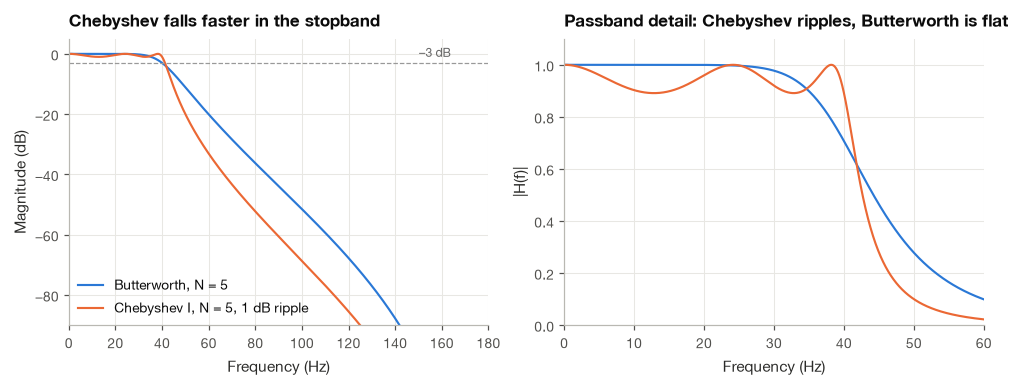

In [10]:
N = 5
b_bw, a_bw = signal.butter(N, 40, fs=fs)
b_ch, a_ch = signal.cheby1(N, 1.0, 40, fs=fs)
f_axis = np.linspace(0.01, fs / 2, 4000)
_, H_bw = signal.freqz(b_bw, a_bw, worN=f_axis, fs=fs)
_, H_ch = signal.freqz(b_ch, a_ch, worN=f_axis, fs=fs)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for H, color, label in [(H_bw, C[0], "Butterworth, N = 5"), (H_ch, C[1], "Chebyshev I, N = 5, 1 dB ripple")]:
    axes[0].plot(f_axis, 20 * np.log10(np.abs(H)), color=color, label=label)
    axes[1].plot(f_axis, np.abs(H), color=color, label=label)
axes[0].axhline(-3, color="0.6", lw=0.8, ls="--")
axes[0].text(150, -1, "−3 dB", fontsize=8, color="0.4")
axes[0].set(xlim=(0, fs / 2), ylim=(-90, 5), xlabel="Frequency (Hz)", ylabel="Magnitude (dB)",
            title="Chebyshev falls faster in the stopband")
axes[0].legend(loc="lower left")
axes[1].set(xlim=(0, 60), ylim=(0, 1.1), xlabel="Frequency (Hz)", ylabel="|H(f)|",
            title="Passband detail: Chebyshev ripples, Butterworth is flat")
plt.show()

At 60 Hz the Chebyshev filter is far below the Butterworth filter in the left panel; in the right panel the Butterworth response is smooth and monotonic, while the Chebyshev gain oscillates between 1 and $10^{-1/20} \approx 0.89$ before plunging. Neither is "better"; they answer different questions.

(sec-8-1-6)=
## 8.1.6 Typical Specifications for Biomedical Signals

Each biosignal comes with conventional pass bands that balance two risks: removing too little noise and removing part of the signal. The table collects common choices. I treat them as starting points, not laws; the right band always depends on the question being asked.

| Signal and use | Typical pass band | Why the lower edge | Why the upper edge | Sources |
|---|---|---|---|---|
| ECG, monitoring and rhythm display | 0.5–40 Hz | suppress respiratory baseline wander and motion | suppress muscle noise and mains hum | {cite:p}`clifford2006,webster2010` |
| ECG, diagnostic 12-lead | 0.05–150 Hz | keep the ST segment undistorted (0.67 Hz is acceptable for zero-phase digital filters) | keep QRS notches and amplitude; 250 Hz for children | {cite:p}`kligfield2007` |
| EEG, routine analysis | about 0.5–70 Hz, plus a 50/60 Hz notch | remove electrode drift and sweat potentials | keep beta and low gamma, reject EMG and mains | {cite:p}`nuwer1998,sornmo2005` |
| Surface EMG | 20–450 Hz | remove movement artifact and cable motion below 20 Hz | sEMG power is negligible above about 450 Hz | {cite:p}`deluca2010,merletti2004` |
| PPG (pulse waveform) | about 0.5–8 Hz | remove slow drift and respiratory baseline | keep the first harmonics of the pulse and the dicrotic notch | {cite:p}`allen2007,elgendi2012` |

Two remarks make the table more useful. First, the mains frequency is 60 Hz in the Americas, Taiwan, Korea and parts of Japan, and 50 Hz in Europe, most of Asia, Africa and Australia, so a notch filter must be configured for the country where the data were recorded. All MIT-BIH recordings were made in Boston, hence 60 Hz. Second, the lower edge is often where clinical damage happens. A 0.5 Hz high-pass filter removes most baseline wander, but if it is a causal analog-style filter it also distorts the ST segment, which is exactly the part of the ECG used to detect myocardial ischemia. We quantify that effect in Section 13.2.

```{note}
"Removing noise" in one analysis may be "removing signal" in another. The slow PPG baseline that a 0.5 Hz high-pass filter discards carries the respiratory rate (Section 22.3), and the 60–150 Hz band that an ECG monitor discards contains the late potentials that some risk-stratification methods look for.
```

(sec-8-1-7)=
## 8.1.7 Filtering a Noisy ECG, Step by Step

We now apply the four filter types to thirty seconds of record 105 (lead MLII, 860–890 s). I picked this stretch because it contains every common ECG contaminant at once: baseline wander, a burst of electrode-motion artifact, muscle noise and the 60 Hz line. The aim here is to watch the four filter *types* act on a real trace and to read their effect in both domains. A complete, beginner-oriented cleaning pipeline, with each noise treated in its own section, is built in [Chapter 12](../ch18_ecg_preprocessing/index.md).

### Step 1: Load the record and look at it

We read only the samples we need and check the basic numbers before plotting anything.

In [11]:
fs = 360
t0 = 860
rec = wfdb.rdrecord("../data/mitdb/105", channels=[0], sampfrom=t0 * fs, sampto=(t0 + 30) * fs)
ecg = rec.p_signal[:, 0]
t = t0 + np.arange(ecg.size) / fs
print(f"Lead {rec.sig_name[0]}, {ecg.size} samples at {fs} Hz ({ecg.size / fs:.0f} s), units {rec.units[0]}")
print(f"Amplitude range: {ecg.min():.2f} to {ecg.max():.2f} mV")

Lead MLII, 10800 samples at 360 Hz (30 s), units mV
Amplitude range: -1.29 to 2.44 mV


### Step 2: Inspect the spectrum

Before choosing any cutoff, I always look at the spectrum to see where the unwanted energy actually sits. We estimate the power spectral density with Welch's method ([Section 7.3](../ch12_spectral_estimation/index.md)) using 4096-sample segments, which gives a frequency resolution of about 0.09 Hz.

60 Hz line: 17.3 dB above its neighbors, amplitude about 9.2 µV
120 Hz line: 13.8 dB above its neighbors, amplitude about 1.2 µV


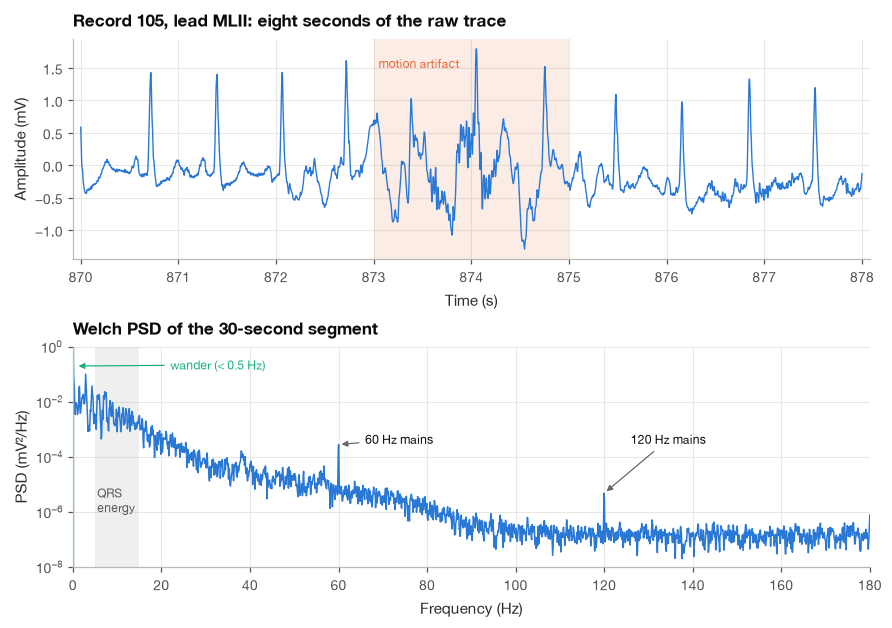

In [12]:
f_raw, P_raw = signal.welch(ecg, fs=fs, nperseg=4096)
for f_line in (60, 120):
    k = np.argmin(np.abs(f_raw - f_line))
    neighbors = np.r_[P_raw[k - 12:k - 4], P_raw[k + 5:k + 13]]
    floor = np.median(neighbors)
    amplitude = np.sqrt(2 * np.sum(P_raw[k - 3:k + 4] - floor) * f_raw[1])   # line power -> sine amplitude
    print(f"{f_line} Hz line: {10 * np.log10(P_raw[k] / floor):.1f} dB above its neighbors, "
          f"amplitude about {1000 * amplitude:.1f} µV")

fig, axes = plt.subplots(2, 1, figsize=(8, 5.6))
view = (t >= 870) & (t <= 878)
axes[0].plot(t[view], ecg[view], color=C[0], lw=0.9)
axes[0].axvspan(873, 875, color=C[1], alpha=0.12, lw=0)
axes[0].text(873.05, 1.5, "motion artifact", fontsize=8, color=C[1])
axes[0].set(xlabel="Time (s)", ylabel="Amplitude (mV)", title="Record 105, lead MLII: eight seconds of the raw trace")
axes[1].semilogy(f_raw, P_raw, color=C[0], lw=1.0)
axes[1].axvspan(0, 0.5, color=C[2], alpha=0.15, lw=0)
axes[1].axvspan(5, 15, color="0.6", alpha=0.15, lw=0)
for f_line in (60, 120):
    axes[1].annotate(f"{f_line} Hz mains", (f_line, P_raw[np.argmin(np.abs(f_raw - f_line))]),
                     xytext=(f_line + 6, 3e-4), fontsize=8, arrowprops=dict(arrowstyle="-|>", color="0.4", lw=0.8))
axes[1].annotate("wander (< 0.5 Hz)", (0.6, 0.2), xytext=(22, 0.15), fontsize=8, color=C[2],
                 arrowprops=dict(arrowstyle="-|>", color=C[2], lw=0.8))
axes[1].text(5.5, 1e-6, "QRS\nenergy", fontsize=8, color="0.35")
axes[1].set(xlim=(0, 180), ylim=(1e-8, 1), xlabel="Frequency (Hz)", ylabel="PSD (mV²/Hz)",
            title="Welch PSD of the 30-second segment")
plt.show()

The spectrum falls by five to six decades from the baseline region to 180 Hz. Wander and motion dominate the lowest frequencies, the QRS energy is concentrated between roughly 5 and 15 Hz, and the mains hum appears as narrow lines at 60 and 120 Hz on top of a broad muscle-noise floor. The 60 Hz line is conspicuous on the logarithmic axis, yet its amplitude is only about 9 µV, a hundred times smaller than the R waves.

### Step 3: Design the four filters

I use Butterworth filters of modest order, stored as second-order sections (`output="sos"`) for numerical safety (Section 15.3):

- low-pass at 40 Hz (order 4), against muscle noise and mains hum;
- high-pass at 0.5 Hz (order 2), against baseline wander;
- band-pass 0.5–40 Hz (order 2 per edge), the usual monitoring band;
- band-stop 58–62 Hz (order 2 per edge), a crude notch for the mains line (Section 15.4 builds better ones).

Rather than trusting the cutoffs, we print each filter's gain at four frequencies that matter for this recording.

In [13]:
filters = {
    "Low-pass 40 Hz": signal.butter(4, 40, "lowpass", fs=fs, output="sos"),
    "High-pass 0.5 Hz": signal.butter(2, 0.5, "highpass", fs=fs, output="sos"),
    "Band-pass 0.5–40 Hz": signal.butter(2, [0.5, 40], "bandpass", fs=fs, output="sos"),
    "Band-stop 58–62 Hz": signal.butter(2, [58, 62], "bandstop", fs=fs, output="sos"),
}
probe = np.array([0.2, 10.0, 60.0, 100.0])
gains = {name: 20 * np.log10(np.abs(signal.sosfreqz(sos, worN=probe, fs=fs)[1]))
         for name, sos in filters.items()}
print("Gain in dB at:", ", ".join(f"{f:g} Hz" for f in probe))
print(pd.DataFrame(gains, index=[f"{f:g} Hz" for f in probe]).T.round(1).to_string())

Gain in dB at: 0.2 Hz, 10 Hz, 60 Hz, 100 Hz
                     0.2 Hz  10 Hz  60 Hz  100 Hz
Low-pass 40 Hz          0.0   -0.0  -16.1   -41.2
High-pass 0.5 Hz      -16.0   -0.0   -0.0    -0.0
Band-pass 0.5–40 Hz   -16.2   -0.0   -8.8   -20.8
Band-stop 58–62 Hz     -0.0   -0.0  -79.9    -0.0


The table is the tolerance scheme in miniature. Every filter keeps 10 Hz within a fraction of a decibel, so the QRS complex will survive. The high-pass filter, however, attenuates 0.2 Hz by only about 16 dB: with its −3 dB point at 0.5 Hz and an order of two, a large part of the wander band lies in its transition region.

### Step 4: Apply the filters and compare before and after

To keep the focus on magnitude responses we apply the filters with `signal.sosfiltfilt`, which runs each filter forward and then backward so that its phase cancels. Section 13.2 explains why this matters and when it is allowed.

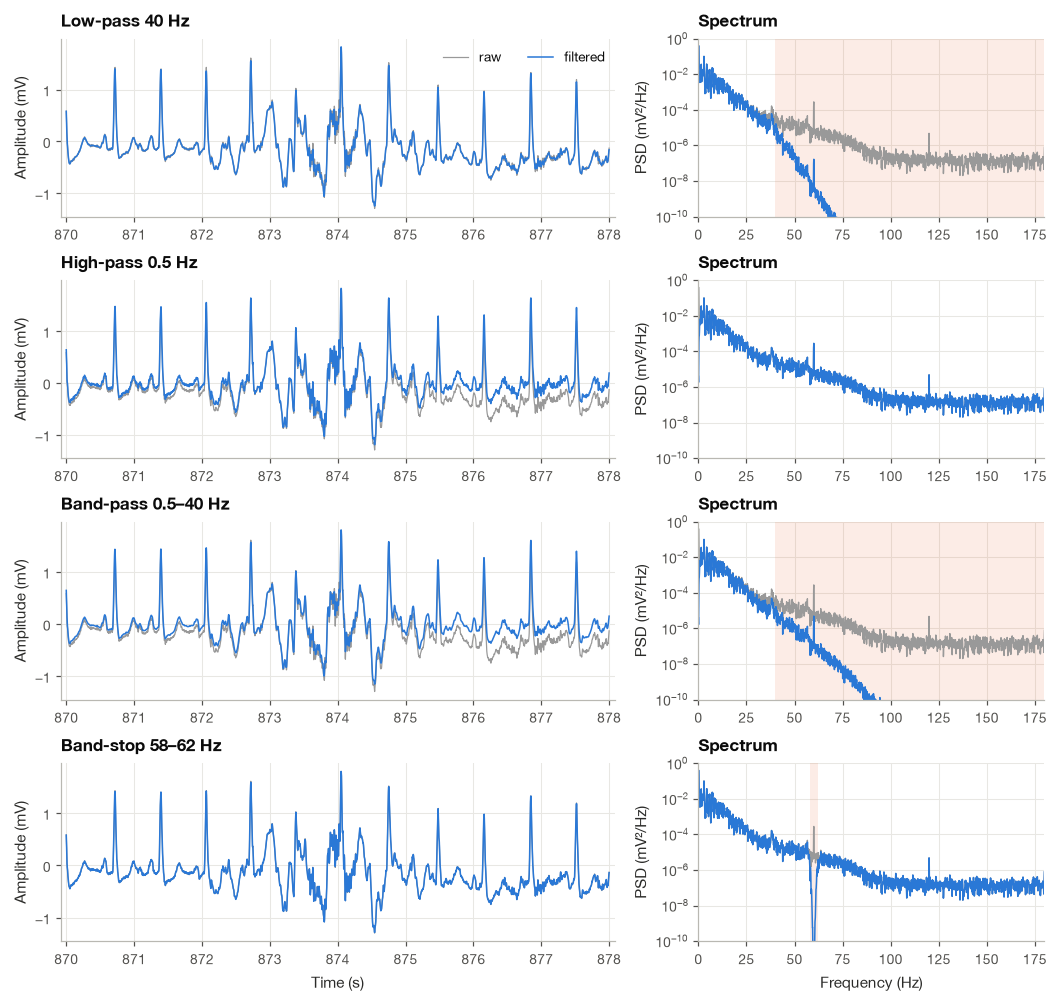

In [14]:
filtered = {name: signal.sosfiltfilt(sos, ecg) for name, sos in filters.items()}

stop_regions = {"Low-pass 40 Hz": [(40, 180)], "High-pass 0.5 Hz": [(0, 0.5)],
                "Band-pass 0.5–40 Hz": [(0, 0.5), (40, 180)], "Band-stop 58–62 Hz": [(58, 62)]}
fig, axes = plt.subplots(4, 2, figsize=(9.5, 9), gridspec_kw={"width_ratios": [1.6, 1]})
for row, (name, y) in enumerate(filtered.items()):
    ax = axes[row, 0]
    ax.plot(t[view], ecg[view], color="0.6", lw=0.8, label="raw")
    ax.plot(t[view], y[view], color=C[0], lw=1.0, label="filtered")
    ax.set(ylabel="Amplitude (mV)", title=name)
    ax = axes[row, 1]
    f_y, P_y = signal.welch(y, fs=fs, nperseg=4096)
    ax.semilogy(f_raw, P_raw, color="0.6", lw=0.9, label="raw")
    ax.semilogy(f_y, P_y, color=C[0], lw=1.0, label="filtered")
    for lo, hi in stop_regions[name]:
        ax.axvspan(lo, hi, color=C[1], alpha=0.12, lw=0)
    ax.set(xlim=(0, 180), ylim=(1e-10, 1), ylabel="PSD (mV²/Hz)", title="Spectrum")
axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Frequency (Hz)")
axes[0, 0].legend(loc="upper right", ncols=2)
plt.show()

The time-domain column already tells most of the story. The low-pass filter cleans the fuzz from the baseline but leaves the wander; the high-pass filter flattens the wander but keeps the fuzz; the band-pass filter does both. The band-stop filter changes so little that its two traces are almost indistinguishable, because the 60 Hz component in this record has an amplitude of only about 0.01 mV. The spectral column shows each filter carving its stopband (shaded) out of the raw spectrum.

Notice also what *none* of the filters removes: the electrode-motion artifact between about 873 and 875 s. Its spectrum overlaps that of the ECG itself, so any filter that removed it would also remove the QRS complexes. Frequency-selective filtering only works when signal and noise live in different bands; artifacts that violate this assumption need other tools, such as the adaptive filters of [Section 16.3](../ch16_noise_removal/index.md).

### Step 5: Check the result quantitatively

Pictures can mislead, so we measure the change in power in four bands. The helper integrates the Welch PSD between two frequencies.

In [15]:
def band_power(x, fs, lo, hi, nperseg=4096):
    """Power of x between lo and hi Hz, from a Welch PSD estimate."""
    f, P = signal.welch(x, fs=fs, nperseg=nperseg)
    sel = (f >= lo) & (f <= hi)
    return np.trapezoid(P[sel], f[sel])


bands = {"< 0.5 Hz (wander)": (0, 0.5), "5-15 Hz (QRS)": (5, 15),
         "59.5-60.5 Hz (mains)": (59.5, 60.5), "70-180 Hz (high freq.)": (70, 180)}
rows = {name: {b: 10 * np.log10(band_power(y, fs, *lim) / band_power(ecg, fs, *lim))
               for b, lim in bands.items()} for name, y in filtered.items()}
print("Change in band power relative to the raw ECG (dB):")
print(pd.DataFrame(rows).T.round(1).to_string())

y_hp = filtered["High-pass 0.5 Hz"]
share = band_power(y_hp, fs, 0.2, 0.5) / band_power(y_hp, fs, 0, 0.5)
print(f"\nAfter the high-pass filter, {100 * share:.0f}% of the power below 0.5 Hz lies between 0.2 and 0.5 Hz")

Change in band power relative to the raw ECG (dB):
                     < 0.5 Hz (wander)  5-15 Hz (QRS)  59.5-60.5 Hz (mains)  70-180 Hz (high freq.)
Low-pass 40 Hz                    -0.0           -0.0                 -32.3                   -52.2
High-pass 0.5 Hz                 -26.1           -0.0                  -0.0                    -0.0
Band-pass 0.5–40 Hz              -26.3           -0.0                 -17.5                   -28.2
Band-stop 58–62 Hz                -0.0           -0.0                 -66.2                    -0.0

After the high-pass filter, 85% of the power below 0.5 Hz lies between 0.2 and 0.5 Hz


The QRS band changes by a small fraction of a decibel in every case, while the targeted bands fall by tens of decibels. The wander column for the high-pass filter, about 26 dB, is the weakest result in the table, as Step 3 predicted: most of what remains sits between 0.2 and 0.5 Hz, inside the transition band of a second-order filter. The band-pass filter also removes the mains line less effectively than the order-4 low-pass filter, because its low-pass edge is only of order two.

On real data we cannot compute the error of the cleaned signal, because the true ECG is unknown. The MIT-BIH Noise Stress Test Database {cite:p}`moody1984` exists for exactly this reason: it provides recorded noise that we can add to a clean ECG, so that the truth is known. We add real baseline wander (`bw`) and muscle noise (`ma`) to thirty seconds of the clean record 100, together with a 0.05 mV, 60 Hz sinusoid, and compute the signal-to-noise ratio (SNR) before and after each filter. The last column applies each filter to the clean ECG alone; it is the best SNR the filter could ever reach, limited only by what the filter does to the ECG itself.

In [16]:
s0, n_s = 60 * fs, 30 * fs
clean = wfdb.rdrecord("../data/mitdb/100", channels=[0], sampfrom=s0, sampto=s0 + n_s).p_signal[:, 0]
bw = wfdb.rdrecord("../data/nstdb/bw", channels=[0], sampfrom=s0, sampto=s0 + n_s).p_signal[:, 0]
ma = wfdb.rdrecord("../data/nstdb/ma", channels=[0], sampfrom=s0, sampto=s0 + n_s).p_signal[:, 0]
t_s = np.arange(n_s) / fs
noisy = clean + bw + 0.5 * ma + 0.05 * np.sin(2 * np.pi * 60 * t_s)
reference = clean - clean.mean()


def snr_db(y, ref):
    """SNR of y with respect to a zero-mean reference signal, in dB."""
    y = y - y.mean()
    return 10 * np.log10(np.sum(ref**2) / np.sum((y - ref) ** 2))


print(f"Input SNR: {snr_db(noisy, reference):.1f} dB")
rows = {name: {"output SNR (dB)": snr_db(signal.sosfiltfilt(sos, noisy), reference),
               "clean ECG only (dB)": snr_db(signal.sosfiltfilt(sos, clean), reference)}
        for name, sos in filters.items()}
print(pd.DataFrame(rows).T.round(1).to_string())

Input SNR: -8.0 dB
                     output SNR (dB)  clean ECG only (dB)
Low-pass 40 Hz                  -8.0                 19.5
High-pass 0.5 Hz                 5.9                 13.4
Band-pass 0.5–40 Hz              7.2                 12.3
Band-stop 58–62 Hz              -8.0                 28.2


Starting from an SNR of about −8 dB (the noise has more power than the ECG, almost all of it baseline wander), the high-pass and band-pass filters raise the SNR by roughly 14–15 dB, while the low-pass and band-stop filters leave it essentially unchanged because they attack noise components that carry little of the total power. The last column is sobering. Even with no noise at all, the 0.5 Hz high-pass filter changes the clean ECG enough to cap the SNR at about 13 dB: it removes the ECG's own slow components and reshapes the low-frequency parts of the beat. Every filter both removes noise and alters the signal, and a good design balances the two.

(sec-8-1-8)=
## 8.1.8 Brick-Wall Filtering in the FFT Domain

Equation [(8.2)](#eq-8-2) suggests a tempting shortcut. If we have the whole recording, why not compute its FFT, set every bin outside the band of interest to zero, and transform back? At the DFT bin frequencies this "brick-wall" filter is exactly ideal, with no ripple and no transition band.

The problem appears when we ask what the operation does in time. Multiplying the DFT by a 0/1 mask $M[k]$ is the same as circularly convolving the signal with the inverse DFT of the mask, $m[n] = \operatorname{IDFT}\{M[k]\}$. For a rectangular mask this is a periodic sinc (a Dirichlet kernel), the finite-length cousin of equation [(8.4)](#eq-8-4). It has the same slowly decaying oscillating tails, now spread over the *entire* record, and it is centered at $n = 0$, so it rings both before and after every sharp event. Because the convolution is circular, the tail of the last beat in the record also leaks into the first.

The next cell builds the brick-wall filter, extracts its equivalent impulse response by filtering a unit impulse, and compares it with a Butterworth band-pass filter of the same nominal band, 5–15 Hz, a band typically used to emphasize the QRS complex before detection (Section 19.1).

In [17]:
def brickwall(x, fs, lo, hi):
    """Zero all FFT bins outside [lo, hi] Hz and transform back (ideal mask filter)."""
    X = np.fft.rfft(x)
    f = np.fft.rfftfreq(x.size, 1 / fs)
    X[(f < lo) | (f > hi)] = 0
    return np.fft.irfft(X, n=x.size)


fs = 360
rec = wfdb.rdrecord("../data/mitdb/105", channels=[0], sampfrom=500 * fs, sampto=510 * fs)
ecg10 = rec.p_signal[:, 0]
t10 = np.arange(ecg10.size) / fs
sos_bp = signal.butter(2, [5, 15], "bandpass", fs=fs, output="sos")

y_brick = brickwall(ecg10, fs, 5, 15)
y_butter = signal.sosfiltfilt(sos_bp, ecg10)

impulse = np.zeros(ecg10.size)
impulse[ecg10.size // 2] = 1.0
m_brick = brickwall(impulse, fs, 5, 15)
m_butter = signal.sosfiltfilt(sos_bp, impulse)

lag = (np.arange(ecg10.size) - ecg10.size // 2) / fs
far = np.abs(lag) > 0.5
print(f"Energy of the equivalent impulse response beyond ±0.5 s: "
      f"brick-wall {100 * np.sum(m_brick[far]**2) / np.sum(m_brick**2):.1f}%, "
      f"Butterworth {100 * np.sum(m_butter[far]**2) / np.sum(m_butter**2):.3f}%")

edge = np.zeros(ecg10.size)
edge[-1] = 1.0
wrap = brickwall(edge, fs, 5, 15)
print(f"Impulse at the last sample: largest response in the first 0.25 s = {np.max(np.abs(wrap[:fs // 4])):.4f}"
      f" (peak response {np.max(np.abs(wrap)):.4f})")

Energy of the equivalent impulse response beyond ±0.5 s: brick-wall 2.0%, Butterworth 0.000%
Impulse at the last sample: largest response in the first 0.25 s = 0.0552 (peak response 0.0561)


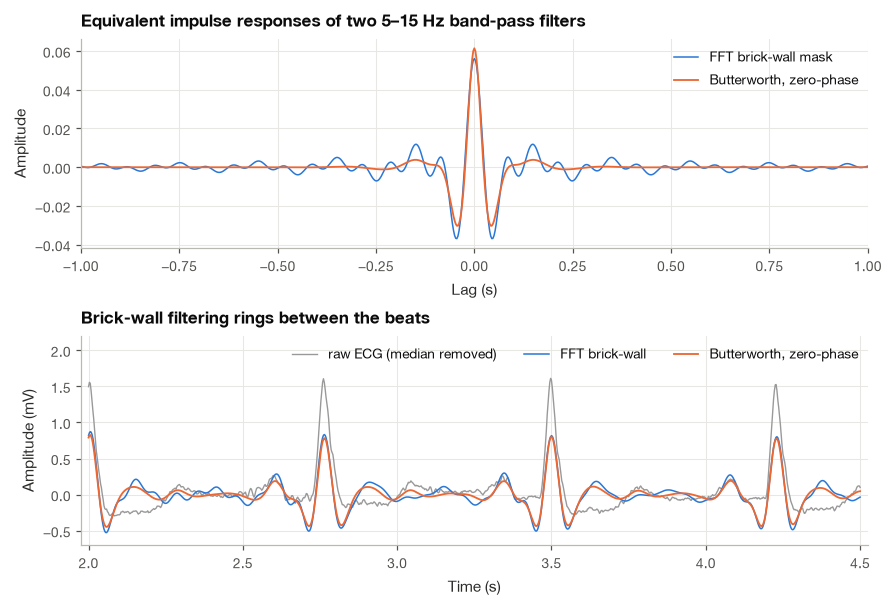

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5.4))
axes[0].plot(lag, m_brick, color=C[0], lw=1.0, label="FFT brick-wall mask")
axes[0].plot(lag, m_butter, color=C[1], lw=1.2, label="Butterworth, zero-phase")
axes[0].set(xlim=(-1, 1), xlabel="Lag (s)", ylabel="Amplitude",
            title="Equivalent impulse responses of two 5–15 Hz band-pass filters")
axes[0].legend(loc="upper right")

view = (t10 >= 2) & (t10 <= 4.5)
axes[1].plot(t10[view], ecg10[view] - np.median(ecg10), color="0.6", lw=0.9, label="raw ECG (median removed)")
axes[1].plot(t10[view], y_brick[view], color=C[0], lw=1.0, label="FFT brick-wall")
axes[1].plot(t10[view], y_butter[view], color=C[1], lw=1.2, label="Butterworth, zero-phase")
axes[1].set(ylim=(-0.7, 2.2), xlabel="Time (s)", ylabel="Amplitude (mV)",
            title="Brick-wall filtering rings between the beats")
axes[1].legend(loc="upper right", ncols=3)
plt.show()

The brick-wall impulse response keeps oscillating at the band edges long after the main lobe has died away, and the filtered ECG shows those oscillations as wavelets that appear before and after every QRS complex, in the stretches where the true signal is quiet. The Butterworth filter, whose transition band is gentle, has a compact impulse response and leaves the inter-beat intervals clean. The printout also confirms the wrap-around: an impulse placed at the very last sample of the record produces an almost full-size response at the very beginning, something no real-time filter could ever do.

For me this is the deeper lesson of the section. Sharpness in frequency and compactness in time pull against each other, a trade-off as unavoidable as the uncertainty principle of Chapter 23. A brick-wall mask is the extreme of sharpness, and it pays with maximal ringing. Practical filter design chooses a transition width that is just narrow enough for the job.

```{important}
FFT masking is still useful for quick exploratory work on long stationary signals, and for removing a single narrow spectral line when the record contains no sharp transients. For physiological waveforms with fast deflections (QRS complexes, spikes, stimulus artifacts), use a designed filter with a finite transition band instead.
```

## Summary

A filter is an LTI system whose frequency response passes some frequency bands and attenuates others; it can modify a signal, extract a component or remove interference, and it can be an analog circuit or an algorithm applied either by convolution in time or by multiplication in frequency. The ideal low-pass, high-pass, band-pass and band-stop filters are simple to define but impossible to build: the inverse DTFT of an ideal low-pass response is the sinc sequence $\sin(\Omega_c n)/(\pi n)$, which is infinitely long, noncausal and not absolutely summable. Practical filters are therefore specified by a tolerance scheme of passband and stopband edges, passband ripple $\delta_p$ and stopband ripple $\delta_s$, with $A_p = 20\log_{10}\big((1+\delta_p)/(1-\delta_p)\big)$ and $A_s = -20\log_{10}\delta_s$ as their decibel forms. Approximation families such as Butterworth (maximally flat) and Chebyshev (equiripple, sharper) distribute the unavoidable error in different ways, and biomedical practice has settled on typical bands for each signal type.

The noisy ECG example showed that filters succeed only when signal and noise occupy different frequency ranges, and that the transition band determines what really happens near a cutoff. The brick-wall experiment showed that the sharpest possible frequency response produces the longest ringing in time. The next section looks at the half of the frequency response we have so far ignored, the phase, and shows why it decides whether a filtered waveform keeps its shape and its timing. Chapters [14](../ch14_fir/index.md) and 15 then turn specifications into actual FIR and IIR designs.

## Exercises

1. Starting from the definitions, sketch the four ideal responses on $-\pi \le \Omega \le \pi$ and verify the relations [(8.3)](#eq-8-3). Then derive the impulse response of the ideal high-pass filter, $h_{\text{HP}}[n] = \delta[n] - \sin(\Omega_c n)/(\pi n)$, and of the ideal band-pass filter in terms of two sinc sequences.
2. A filter specification lists a passband ripple of 0.2 dB and a stopband attenuation of 55 dB. Compute $\delta_p$ and $\delta_s$ by hand using [(8.7)](#eq-8-7), check the small-ripple approximation $A_p \approx 17.37\,\delta_p$, and verify your numbers with the functions in Section 8.1.4.
3. Show that the ideal low-pass impulse response [(8.4)](#eq-8-4) has energy $\sum_n h_{\text{LP}}^2[n] = \Omega_c/\pi$ by applying Parseval's relation to its DTFT. Confirm the result numerically for $f_c = 40$ Hz at $f_s = 360$ Hz, and explain why finite energy does not imply BIBO stability.
4. Use `signal.buttord`, `signal.cheb1ord` and `signal.ellipord` to find the minimum orders for an EEG anti-aliasing specification at $f_s = 500$ Hz: passband edge 70 Hz with 0.5 dB ripple, stopband edge 100 Hz with 60 dB attenuation. Plot the three magnitude responses in dB on one figure and comment on where each family places its error.
5. Repeat the filtering experiment of [Section 8.1.7](#sec-8-1-7) with the high-pass cutoff raised to 1 Hz and the order raised to 4. How do the band powers in the table change? Plot a few beats and describe what happens to the T wave and the ST segment.
6. Apply the FFT brick-wall filter of [Section 8.1.8](#sec-8-1-8) to a synthetic signal consisting of a unit step at $t = 5$ s in a 10 s record sampled at 360 Hz, with a 0.5 Hz high-pass mask. Plot the result, measure how far before the step the ringing becomes visible, and explain the observation using the equivalent impulse response.

## Further Reading

{cite:t}`oppenheim2010` (Chapter 5) gives the classical treatment of filter specifications, tolerance schemes and the impossibility of ideal filters, and {cite:t}`proakis2007` covers the same ground with many worked design examples. {cite:t}`smith1997` explains the trade-off between sharpness in frequency and ringing in time with especially clear figures, which is a good companion to Section 8.1.8. For the biomedical bands, {cite:t}`kligfield2007` is the reference for diagnostic ECG bandwidth, {cite:t}`deluca2010` justifies the 20 Hz high-pass corner for surface EMG, and {cite:t}`semmlow2014` discusses filter choices across many physiological signals.